# Pakistan E-commerce Dataset Analysis

Run the cells in order. The notebook loads the local CSV, performs basic preprocessing, and starts the EDA. Plots are saved under `plots/`.

## Step 1 — Preprocessing

This dataset contains item-level rows. Blank padding rows are removed; potentially meaningful unusual values are reported rather than silently discarded.

In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path.cwd() / 'DATASET' / 'Pakistan Largest Ecommerce Dataset.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError('Dataset not found. Place the source CSV under DATASET and run from the project root.')

category_columns = [
    'status', 'category_name_1', 'payment_method', 'BI Status',
    'sales_commission_code', 'M-Y', 'FY', 'Customer Since',
]
dtype_map = {
    'item_id': 'Int64', 'Customer ID': 'Int64', 'increment_id': 'string',
    'Year': 'Int16', 'Month': 'Int8', 'qty_ordered': 'Int32',
    'price': 'float64', 'grand_total': 'float64', 'discount_amount': 'float64',
    'sku': 'string', ' MV ': 'string',
}
dtype_map.update({column: 'category' for column in category_columns})

df = pd.read_csv(
    DATA_PATH,
    usecols=lambda column: not column.startswith('Unnamed:'),
    dtype=dtype_map,
    na_values=[r'\N'],
    low_memory=False,
)
physical_rows = len(df)
df = df.loc[df['item_id'].notna()].copy()
blank_rows_removed = physical_rows - len(df)
exact_duplicates = int(df.duplicated().sum())
if exact_duplicates:
    df = df.drop_duplicates().copy()

for column in ['created_at', 'Working Date']:
    df[column] = pd.to_datetime(df[column], format='%m/%d/%Y', errors='coerce')
df['order_year'] = df['created_at'].dt.year.astype('Int16')
df['order_month'] = df['created_at'].dt.month.astype('Int8')
df['order_day'] = df['created_at'].dt.day.astype('Int8')
df['order_weekday'] = df['created_at'].dt.day_name().astype('category')

print(f'Physical rows: {physical_rows:,}')
print(f'Blank rows removed: {blank_rows_removed:,}')
print(f'Exact duplicate rows removed: {exact_duplicates:,}')
print(f'Cleaned shape: {df.shape}')
print(f'Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MiB')

missing = pd.DataFrame({
    'count': df.isna().sum(),
    'percent': (df.isna().mean() * 100).round(2),
})
print('\nMissing values:')
print(missing.loc[missing['count'] > 0].to_string())
print('\nNumerical summary:')
print(df.describe(include='number').T.to_string())
print('\nPotential data-quality issues:')
quality_checks = {
    'invalid created_at dates': int(df['created_at'].isna().sum()),
    'invalid Working Date values': int(df['Working Date'].isna().sum()),
    'negative prices': int((df['price'] < 0).sum()),
    'zero prices': int((df['price'] == 0).sum()),
    'nonpositive quantities': int((df['qty_ordered'] <= 0).sum()),
    'negative grand_total values': int((df['grand_total'] < 0).sum()),
    'negative discount values': int((df['discount_amount'] < 0).sum()),
}
print(pd.Series(quality_checks).to_string())
valid_dates = df['created_at'].notna()
print(f"\nSource Year mismatches: {int((valid_dates & (df['Year'] != df['created_at'].dt.year)).sum()):,}")
print(f"Source Month mismatches: {int((valid_dates & (df['Month'] != df['created_at'].dt.month)).sum()):,}")
print('\nMost common statuses:')
print(df['status'].value_counts(dropna=False).head(20).to_string())

Physical rows: 1,048,575
Blank rows removed: 464,051
Exact duplicate rows removed: 0
Cleaned shape: (584524, 25)
Memory usage: 149.7 MiB

Missing values:
                        count  percent
status                     19     0.00
sku                        20     0.00
category_name_1          8014     1.37
sales_commission_code  476179    81.46
Customer Since             11     0.00
Customer ID                11     0.00

Numerical summary:
                    count           mean            std       min        25%       50%        75%         max
item_id          584524.0  565667.074218  200121.173648  211131.0  395000.75  568424.5  739106.25    905208.0
price            584524.0    6348.747531   14949.269515       0.0      360.0     899.0     4070.0   1012625.9
qty_ordered      584524.0       1.296388       3.996061       1.0        1.0       1.0        1.0      1000.0
grand_total      584524.0    8530.618571   61320.814625   -1594.0      945.0    1960.4     6999.0  17888000.0
dis

## Step 2 — Exploratory Data Analysis

Payment and status charts count distinct orders. Price, quantity, and discount analyses use item rows. The order-level fields are checked for consistency before the first row per order is used.

Orders with inconsistent values across item rows:
grand_total varies within order       0
status varies within order            0
payment_method varies within order    0

Item rows: 584,524; distinct orders: 408,782


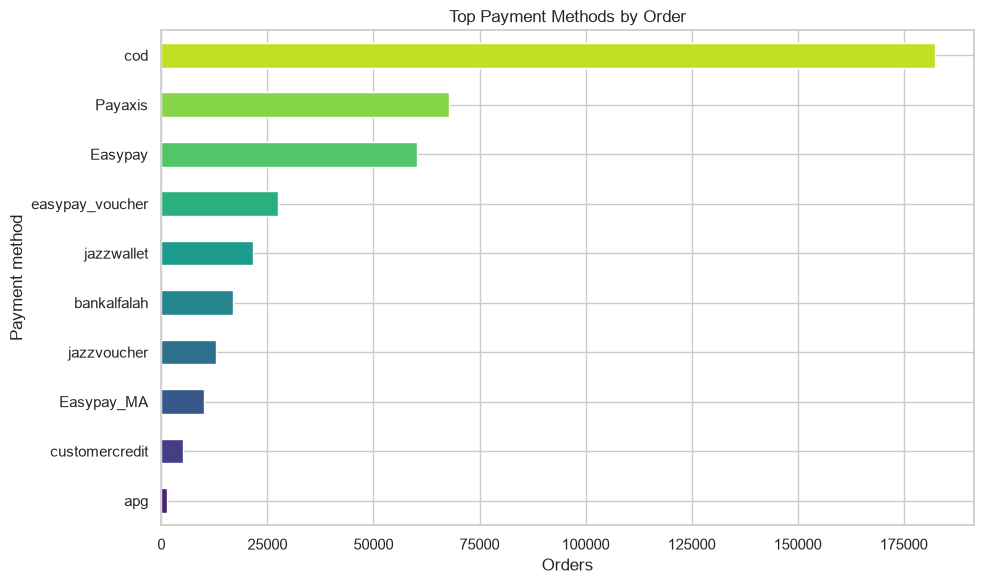

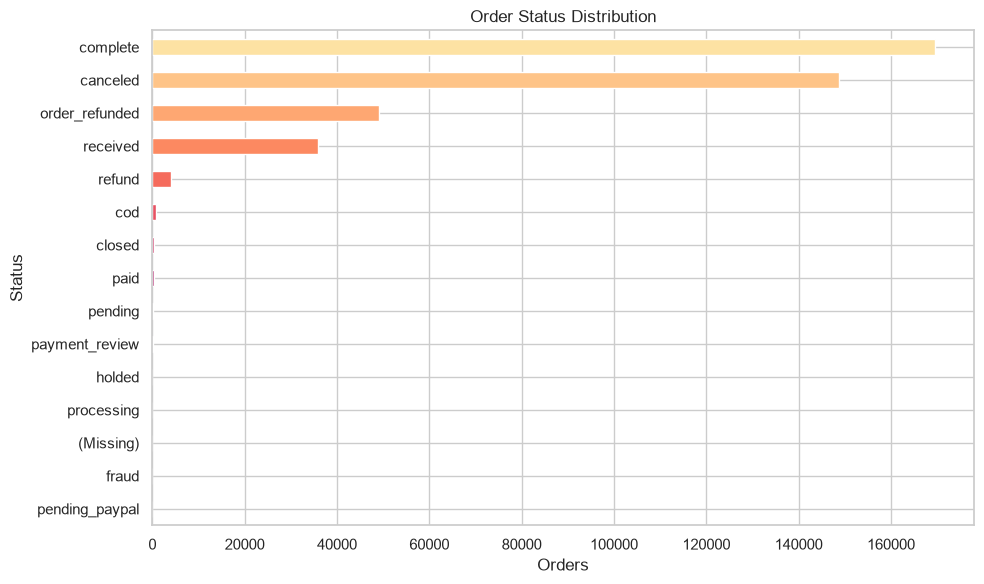

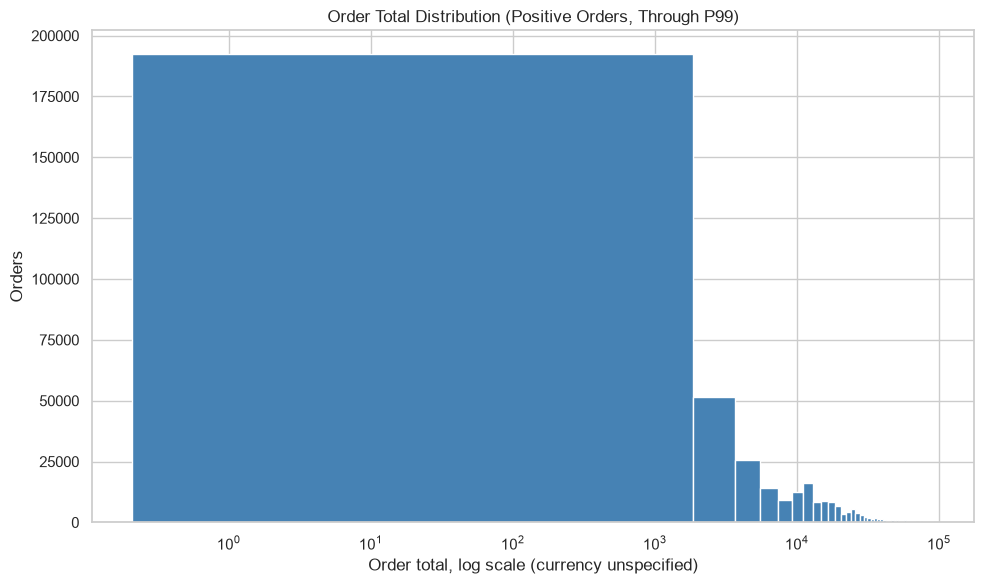

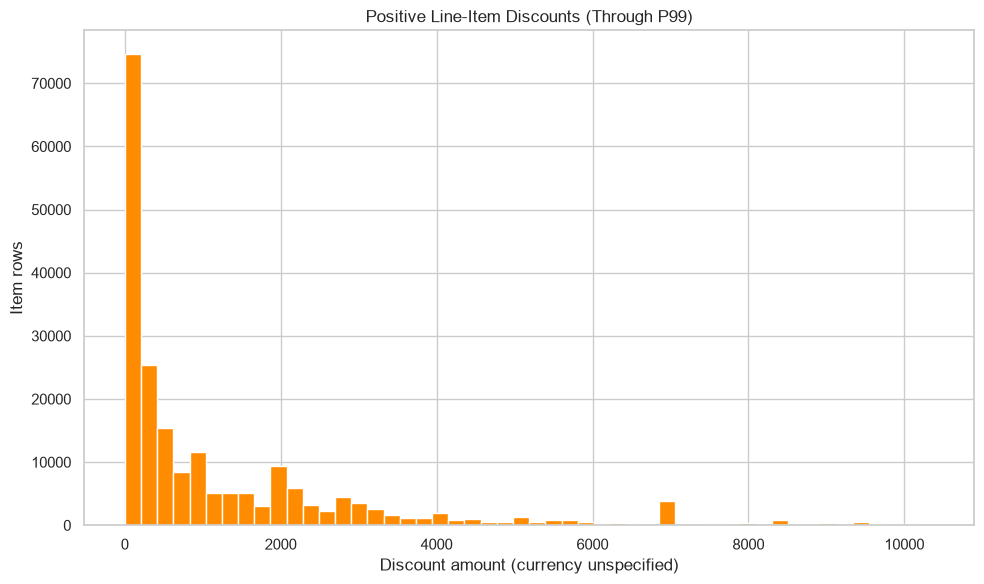

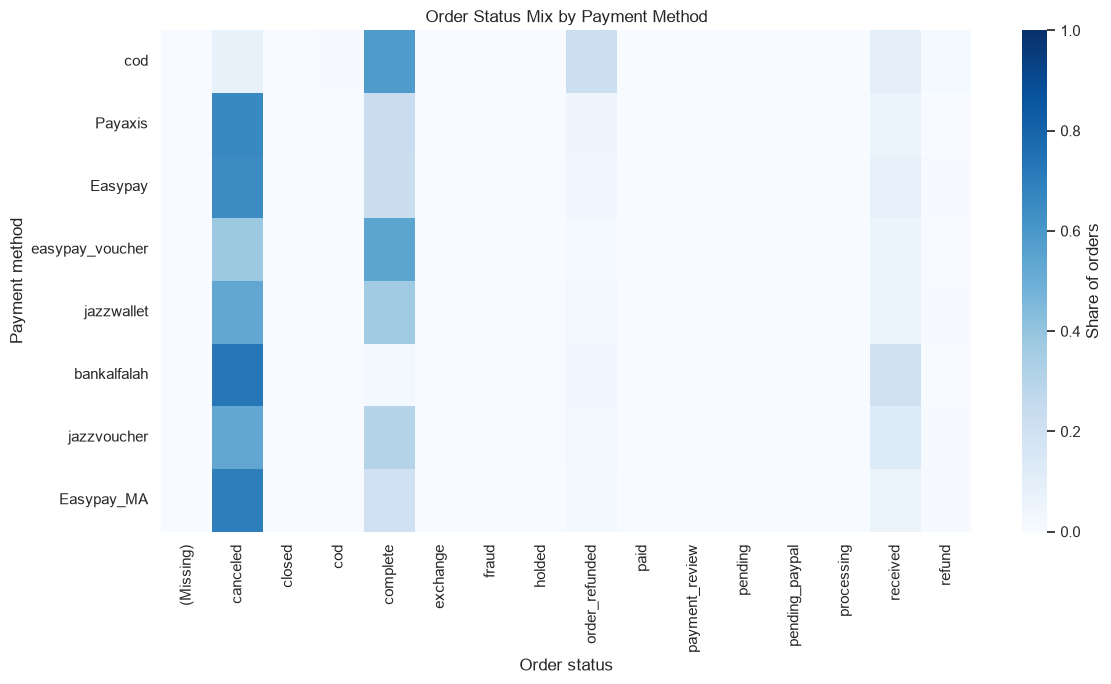


IQR outlier summary:
                q1      q3  lower_fence  upper_fence  outlier_count  outlier_percent  high_outlier_gross_value_share_percent
price        360.0  4070.0      -5205.0       9635.0       105687.0            18.08                                   80.18
qty_ordered    1.0     1.0          1.0          1.0        79310.0            13.57                                   18.44


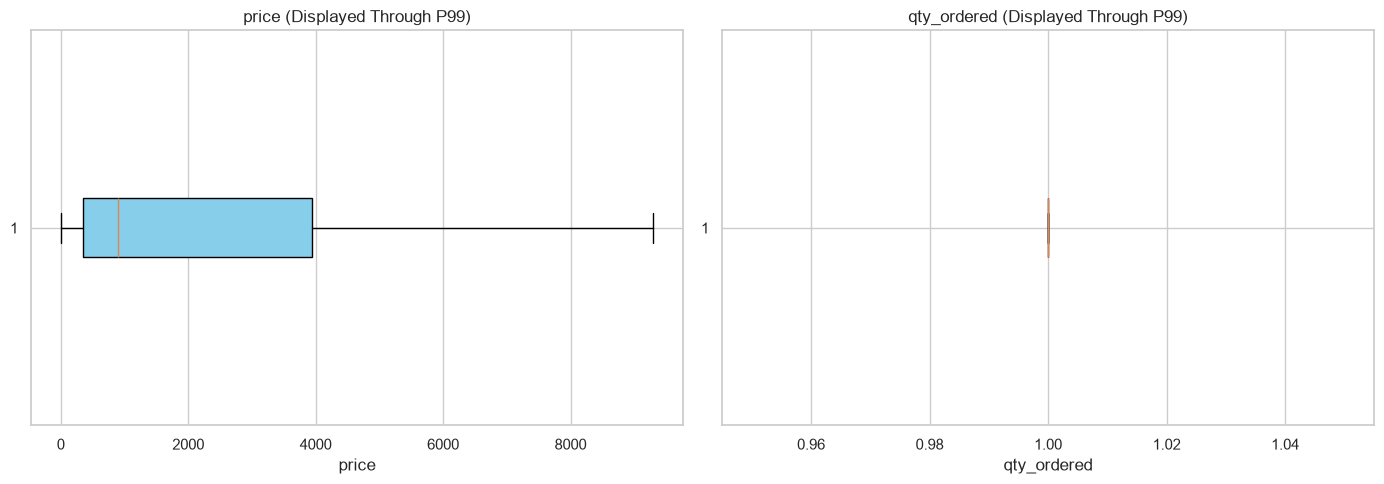


Plots saved to: .\plots


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

PLOT_DIR = Path.cwd() / 'plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
MAX_BOXPLOT_SAMPLE = 100_000

order_groups = df.groupby('increment_id', observed=True, sort=False)
conflicts = pd.Series({
    'grand_total varies within order': int(order_groups['grand_total'].nunique(dropna=True).gt(1).sum()),
    'status varies within order': int(order_groups['status'].nunique(dropna=True).gt(1).sum()),
    'payment_method varies within order': int(order_groups['payment_method'].nunique(dropna=True).gt(1).sum()),
})
print('Orders with inconsistent values across item rows:')
print(conflicts.to_string())
order_df = order_groups.agg(
    grand_total=('grand_total', 'first'),
    status=('status', 'first'),
    payment_method=('payment_method', 'first'),
).reset_index()
print(f'\nItem rows: {len(df):,}; distinct orders: {len(order_df):,}')

payment_counts = order_df['payment_method'].astype('string').fillna('(Missing)').value_counts().head(10)
status_counts = order_df['status'].astype('string').fillna('(Missing)').value_counts().head(15)
fig, ax = plt.subplots(figsize=(10, 6))
payment_counts.sort_values().plot.barh(ax=ax, color=sns.color_palette('viridis', 10))
ax.set(title='Top Payment Methods by Order', xlabel='Orders', ylabel='Payment method')
fig.tight_layout()
fig.savefig(PLOT_DIR / 'top_payment_methods.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 6))
status_counts.sort_values().plot.barh(ax=ax, color=sns.color_palette('magma', 15))
ax.set(title='Order Status Distribution', xlabel='Orders', ylabel='Status')
fig.tight_layout()
fig.savefig(PLOT_DIR / 'order_status_distribution.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

positive_totals = order_df.loc[order_df['grand_total'] > 0, 'grand_total'].dropna()
if not positive_totals.empty:
    total_p99 = positive_totals.quantile(0.99)
    fig, ax = plt.subplots(figsize=(10, 6))
    totals_for_plot = positive_totals.loc[positive_totals <= total_p99]
    total_bins = np.geomspace(totals_for_plot.min(), totals_for_plot.max(), 51)
    ax.hist(totals_for_plot, bins=total_bins, color='steelblue', edgecolor='white')
    ax.set_xscale('log')
    ax.set(title='Order Total Distribution (Positive Orders, Through P99)',
           xlabel='Order total, log scale (currency unspecified)', ylabel='Orders')
    fig.tight_layout()
    fig.savefig(PLOT_DIR / 'order_total_distribution.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

positive_discounts = df.loc[df['discount_amount'] > 0, 'discount_amount'].dropna()
if not positive_discounts.empty:
    discount_p99 = positive_discounts.quantile(0.99)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.hist(positive_discounts.loc[positive_discounts <= discount_p99], bins=50,
            color='darkorange', edgecolor='white')
    ax.set(title='Positive Line-Item Discounts (Through P99)',
           xlabel='Discount amount (currency unspecified)', ylabel='Item rows')
    fig.tight_layout()
    fig.savefig(PLOT_DIR / 'discount_distribution.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

payment_text = order_df['payment_method'].astype('string').fillna('(Missing)')
status_text = order_df['status'].astype('string').fillna('(Missing)')
top_methods = payment_text.value_counts().head(8).index
status_mix = pd.crosstab(payment_text, status_text, normalize='index').reindex(top_methods)
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(status_mix, cmap='Blues', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'Share of orders'})
ax.set(title='Order Status Mix by Payment Method', xlabel='Order status', ylabel='Payment method')
fig.tight_layout()
fig.savefig(PLOT_DIR / 'payment_method_vs_status.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

def iqr_outlier_summary(series):
    values = series.dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outside = (values < lower) | (values > upper)
    return {'q1': q1, 'q3': q3, 'lower_fence': lower, 'upper_fence': upper,
            'outlier_count': int(outside.sum()), 'outlier_percent': 100 * outside.mean()}

line_gross_value = df['price'] * df['qty_ordered']
total_gross_value = line_gross_value.sum()
outlier_results = {}
for column in ['price', 'qty_ordered']:
    result = iqr_outlier_summary(df[column])
    high_mask = df[column] > result['upper_fence']
    high_value = line_gross_value.loc[high_mask].sum()
    result['high_outlier_gross_value_share_percent'] = (
        100 * high_value / total_gross_value if total_gross_value else float('nan')
    )
    outlier_results[column] = result
print('\nIQR outlier summary:')
print(pd.DataFrame(outlier_results).T.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, color in zip(axes, ['price', 'qty_ordered'], ['skyblue', 'lightgreen']):
    values = df[column].dropna()
    p99 = values.quantile(0.99)
    central = values.loc[values <= p99]
    if len(central) > MAX_BOXPLOT_SAMPLE:
        central = central.sample(MAX_BOXPLOT_SAMPLE, random_state=RANDOM_STATE)
    ax.boxplot(central, orientation='horizontal', showfliers=False, patch_artist=True,
               boxprops={'facecolor': color})
    ax.set(title=f'{column} (Displayed Through P99)', xlabel=column)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'price_qty_outliers.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)
print('\nPlots saved to: plots/')

## Step 3 — Trends, categories, and customer patterns

Monthly and weekday trends count distinct orders. Category `price × quantity` is a gross item-value proxy, not profit: the dataset has no product cost or margin field. Cancellation and refund rates below are item-row rates. Customer location cannot be analyzed unless geographic fields exist in the source.

Orders with multiple Customer IDs across item rows: 0

Top months by distinct orders:
            orders  recorded_order_value
month                                   
2017-11-01   57244          6.671199e+08
2016-11-01   55450          2.094304e+08
2018-03-01   35126          3.639408e+08
2017-05-01   20814          1.816435e+08
2018-05-01   19896          3.774394e+08
2018-02-01   19340          2.698817e+08
2017-08-01   13744          8.625869e+07
2017-03-01   13543          1.046668e+08
2016-09-01   13135          7.567103e+07
2017-10-01   12741          9.477182e+07


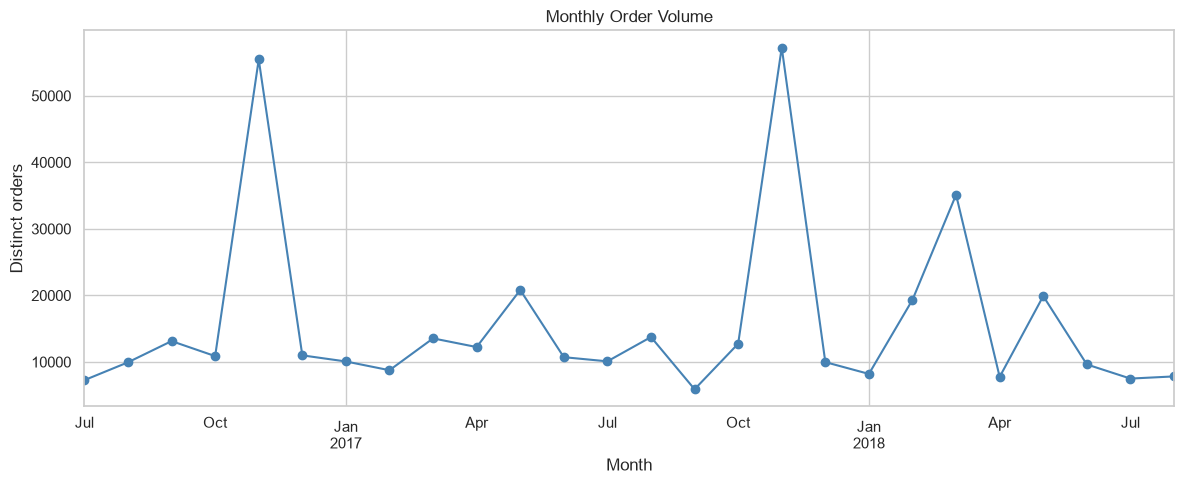


Orders by weekday:
order_date
Monday       53239
Tuesday      54165
Wednesday    55723
Thursday     61377
Friday       89704
Saturday     54491
Sunday       40083

Ten busiest calendar dates (check these against campaign and holiday calendars):
order_date
2016-11-25    11621
2017-11-24     9176
2017-11-17     9098
2017-05-19     6806
2016-11-23     6679
2016-11-24     6356
2018-03-28     6039
2017-11-18     5068
2018-03-27     5038
2018-03-15     4317

Top categories by gross item-value proxy (not profit):
                   item_rows   units  gross_item_value_proxy  cancelled_item_rows  refunded_item_rows  cancellation_rate_pct  refund_rate_pct
category                                                                                                                                     
Mobiles & Tablets     115710  132695           2307710409.01                53715               11655                  46.42            10.07
Appliances             52413   58203            612092739.29 

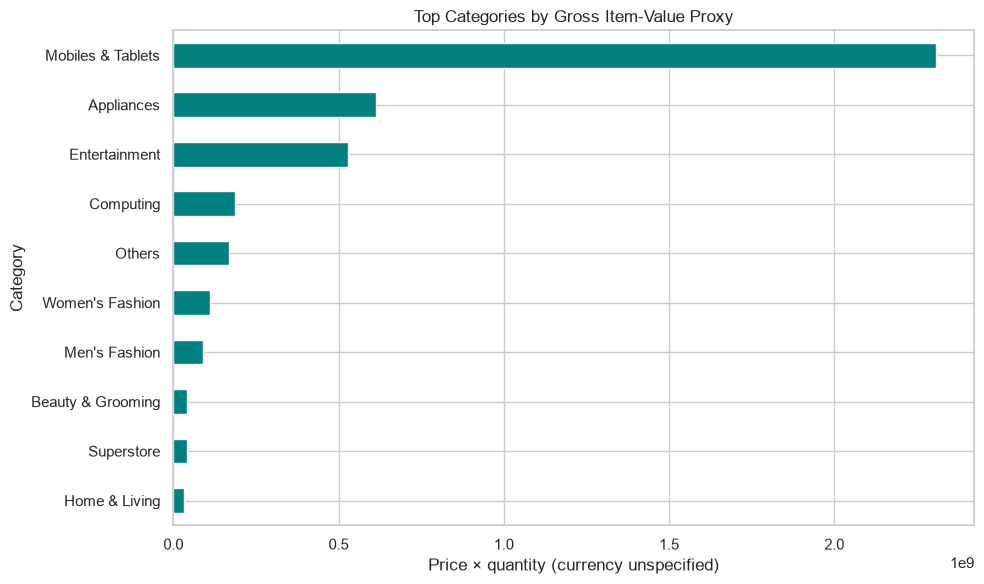


Payment method order/customer counts and provisional outcome rates:
                 orders  customers  cancellation_rate  completed_like_rate  refund_rate
payment_method                                                                         
cod              182449      76068               7.88                67.80        23.69
Payaxis           67912      20779              66.02                29.09         4.79
Easypay           60278      19597              64.75                31.28         3.96
easypay_voucher   27505       8931              38.04                59.88         1.96
jazzwallet        21613       6951              52.92                43.03         4.03
bankalfalah       16912       6542              72.88                22.87         3.88
jazzvoucher       12809       4267              53.12                43.31         3.49
Easypay_MA        10050       4873              70.16                26.73         3.11
customercredit     5120       2711               0.

In [3]:
# Aggregate verified order-level fields and check customer consistency.
order_groups = df.groupby('increment_id', observed=True, sort=False)
customer_conflicts = int(order_groups['Customer ID'].nunique(dropna=True).gt(1).sum())
print(f'Orders with multiple Customer IDs across item rows: {customer_conflicts:,}')

trend_orders = order_groups.agg(
    order_date=('created_at', 'first'),
    customer_id=('Customer ID', 'first'),
    grand_total=('grand_total', 'first'),
    status=('status', 'first'),
    payment_method=('payment_method', 'first'),
).reset_index()

# Time trends: monthly orders and recorded order value (not recognized revenue).
dated_orders = trend_orders.dropna(subset=['order_date']).copy()
dated_orders['month'] = dated_orders['order_date'].dt.to_period('M').dt.to_timestamp()
monthly = (
    dated_orders.groupby('month', sort=True)
    .agg(orders=('increment_id', 'nunique'), recorded_order_value=('grand_total', 'sum'))
)
print('\nTop months by distinct orders:')
print(monthly.sort_values('orders', ascending=False).head(10).to_string())

fig, ax = plt.subplots(figsize=(12, 5))
monthly['orders'].plot(ax=ax, marker='o', color='steelblue')
ax.set(title='Monthly Order Volume', xlabel='Month', ylabel='Distinct orders')
fig.tight_layout()
fig.savefig(PLOT_DIR / 'monthly_order_trend.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts = dated_orders['order_date'].dt.day_name().value_counts().reindex(weekday_order)
print('\nOrders by weekday:')
print(weekday_counts.to_string())
print('\nTen busiest calendar dates (check these against campaign and holiday calendars):')
daily_counts = dated_orders.groupby(dated_orders['order_date'].dt.normalize()).size()
print(daily_counts.sort_values(ascending=False).head(10).to_string())

# Category sales proxy and item-row cancellation/refund rates.
status_text = df['status'].astype('string')
category_items = pd.DataFrame({
    'category': df['category_name_1'].astype('string').fillna('(Missing)'),
    'quantity': df['qty_ordered'],
    'gross_item_value_proxy': df['price'] * df['qty_ordered'],
    'is_cancelled': status_text.eq('canceled').fillna(False).astype('int8'),
    'is_refunded': status_text.isin(['refund', 'order_refunded']).astype('int8'),
})
category_summary = category_items.groupby('category', sort=False).agg(
    item_rows=('quantity', 'size'),
    units=('quantity', 'sum'),
    gross_item_value_proxy=('gross_item_value_proxy', 'sum'),
    cancelled_item_rows=('is_cancelled', 'sum'),
    refunded_item_rows=('is_refunded', 'sum'),
)
category_summary['cancellation_rate_pct'] = (
    100 * category_summary['cancelled_item_rows'] / category_summary['item_rows']
)
category_summary['refund_rate_pct'] = (
    100 * category_summary['refunded_item_rows'] / category_summary['item_rows']
)
known_categories = category_summary.drop(index='(Missing)', errors='ignore')
print('\nTop categories by gross item-value proxy (not profit):')
print(known_categories.sort_values('gross_item_value_proxy', ascending=False).head(10).round(2).to_string())
stable_volume_categories = known_categories.loc[known_categories['item_rows'] >= 100]
print('\nCategory cancellation/refund rates (minimum 100 item rows):')
print(stable_volume_categories.sort_values('cancellation_rate_pct', ascending=False)[
    ['item_rows', 'cancellation_rate_pct', 'refund_rate_pct']
].head(10).round(2).to_string())

top_categories = known_categories.sort_values('gross_item_value_proxy', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(10, 6))
top_categories['gross_item_value_proxy'].sort_values().plot.barh(ax=ax, color='teal')
ax.set(title='Top Categories by Gross Item-Value Proxy',
       xlabel='Price × quantity (currency unspecified)', ylabel='Category')
fig.tight_layout()
fig.savefig(PLOT_DIR / 'category_gross_value_proxy.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# Payment outcomes and customer usage. Completion is a provisional grouping
# of complete/received/paid; validate status semantics before business decisions.
status_by_order = trend_orders['status'].astype('string')
trend_orders['is_cancelled'] = status_by_order.eq('canceled').fillna(False)
trend_orders['is_completed_like'] = status_by_order.isin(['complete', 'received', 'paid'])
trend_orders['is_refunded'] = status_by_order.isin(['refund', 'order_refunded'])
payment_summary = trend_orders.groupby('payment_method', observed=True, dropna=False).agg(
    orders=('increment_id', 'size'),
    customers=('customer_id', 'nunique'),
    cancellation_rate=('is_cancelled', 'mean'),
    completed_like_rate=('is_completed_like', 'mean'),
    refund_rate=('is_refunded', 'mean'),
)
rate_columns = ['cancellation_rate', 'completed_like_rate', 'refund_rate']
payment_summary[rate_columns] = payment_summary[rate_columns] * 100
print('\nPayment method order/customer counts and provisional outcome rates:')
print(payment_summary.sort_values('orders', ascending=False).head(10).round(2).to_string())

customer_order_counts = trend_orders.groupby('customer_id', dropna=True)['increment_id'].size()
if not customer_order_counts.empty:
    repeat_customer_pct = 100 * customer_order_counts.gt(1).mean()
    print(f'\nCustomers with more than one recorded order: {repeat_customer_pct:.2f}%')

geo_columns = [
    column for column in df.columns
    if any(term in column.lower() for term in ['city', 'province', 'region', 'state', 'country', 'location'])
]
print(f'Geographic columns available for location analysis: {geo_columns}')
print('\nStep 3 plots saved to: plots/')

## Step 4 — CPU-optimized cancellation model

This model predicts `canceled` versus known completed-like outcomes (`complete`, `received`, `paid`). Refunds and ambiguous statuses are excluded from training. It uses a chronological holdout to reduce time leakage. Category is represented by the most frequent category among an order's item rows; tree models do not require scaling. Feature importance is associative, not causal.

Eligible orders: 354,258
Target distribution (0 = completed-like, 1 = canceled):
target_cancelled
0    205602
1    148656
Chronological split date: 2018-03-14
Train orders: 281,903; test orders: 72,355

Chronological test-set metrics (canceled is positive class):
Accuracy:  0.7099
Precision: 0.7009
Recall:    0.8381
F1-score:  0.7634
ROC-AUC:   0.7462

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[17504 14451]
 [ 6539 33861]]

Classification report:
                precision    recall  f1-score   support

completed-like       0.73      0.55      0.63     31955
      canceled       0.70      0.84      0.76     40400

      accuracy                           0.71     72355
     macro avg       0.71      0.69      0.69     72355
  weighted avg       0.71      0.71      0.70     72355

Top feature importances (model association, not causation):
categorical__payment_method_cod                0.5130
categorical__payment_method_customercredit     0.0989
categorical__payment_method_Easypay       

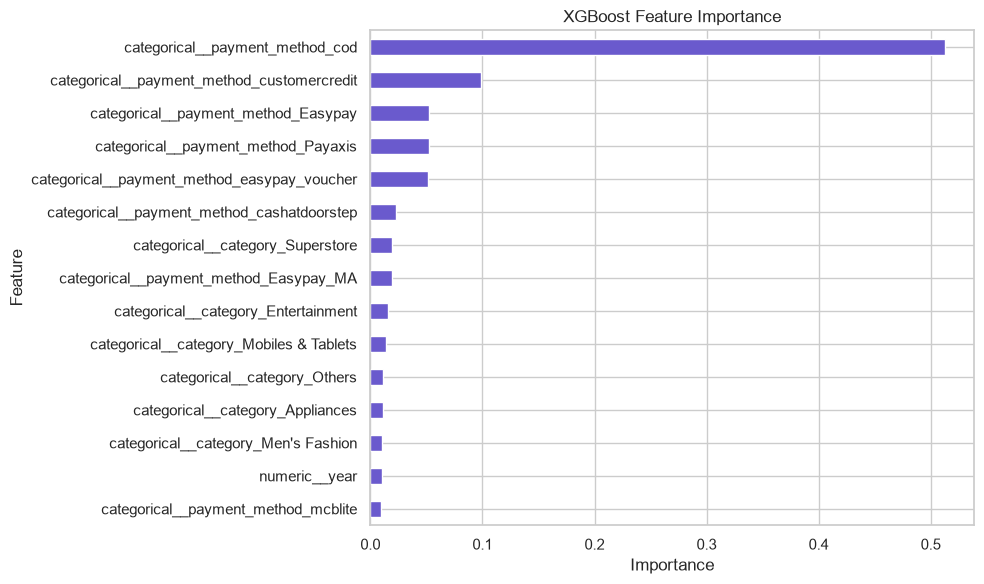

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

# Represent each order by its most frequent item category.
category_rows = pd.DataFrame({
    'increment_id': df['increment_id'].to_numpy(),
    'category': df['category_name_1'].astype('string').fillna('(Missing)').to_numpy(),
})
category_counts = (
    category_rows.groupby(['increment_id', 'category'], sort=False, dropna=False)
    .size()
    .rename('line_count')
    .reset_index()
)
dominant_category = (
    category_counts.sort_values(
        ['increment_id', 'line_count'], ascending=[True, False], kind='stable'
    )
    .drop_duplicates('increment_id')
    .set_index('increment_id')['category']
)
del category_rows, category_counts

model_df = trend_orders.set_index('increment_id')[
    ['order_date', 'payment_method', 'status']
].copy()
model_df['category'] = dominant_category.reindex(model_df.index).fillna('(Missing)')
status_labels = model_df['status'].astype('string')
eligible = status_labels.isin(['canceled', 'complete', 'received', 'paid'])
model_df = model_df.loc[eligible].copy()
status_labels = status_labels.loc[eligible]
model_df['target_cancelled'] = status_labels.eq('canceled').astype('int8')
model_df = model_df.dropna(subset=['order_date'])
model_df['year'] = model_df['order_date'].dt.year.astype('int16')
model_df['month'] = model_df['order_date'].dt.month.astype('int8')
model_df['weekday'] = model_df['order_date'].dt.day_of_week.astype('int8')

print(f'Eligible orders: {len(model_df):,}')
print('Target distribution (0 = completed-like, 1 = canceled):')
print(model_df['target_cancelled'].value_counts().sort_index().to_string())

split_date = model_df['order_date'].quantile(0.80)
train_mask = model_df['order_date'] < split_date
test_mask = ~train_mask
feature_columns = ['payment_method', 'category', 'year', 'month', 'weekday']
categorical_features = ['payment_method', 'category']
numeric_features = ['year', 'month', 'weekday']
X_train = model_df.loc[train_mask, feature_columns].copy()
X_test = model_df.loc[test_mask, feature_columns].copy()
y_train = model_df.loc[train_mask, 'target_cancelled']
y_test = model_df.loc[test_mask, 'target_cancelled']
print(f'Chronological split date: {split_date.date()}')
print(f'Train orders: {len(X_train):,}; test orders: {len(X_test):,}')

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numeric', 'passthrough', numeric_features),
    ],
    verbose_feature_names_out=True,
)
model = XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=4,
    random_state=42,
)
pipeline = Pipeline([('preprocessor', preprocessor), ('model', model)])
pipeline.fit(X_train, y_train)

predictions = pipeline.predict(X_test)
probabilities = pipeline.predict_proba(X_test)[:, 1]
print('\nChronological test-set metrics (canceled is positive class):')
print(f'Accuracy:  {accuracy_score(y_test, predictions):.4f}')
print(f'Precision: {precision_score(y_test, predictions, zero_division=0):.4f}')
print(f'Recall:    {recall_score(y_test, predictions, zero_division=0):.4f}')
print(f'F1-score:  {f1_score(y_test, predictions, zero_division=0):.4f}')
if y_test.nunique() == 2:
    print(f'ROC-AUC:   {roc_auc_score(y_test, probabilities):.4f}')
print('\nConfusion matrix [ [TN, FP], [FN, TP] ]:')
print(confusion_matrix(y_test, predictions, labels=[0, 1]))
print('\nClassification report:')
print(classification_report(y_test, predictions, labels=[0, 1],
                            target_names=['completed-like', 'canceled'], zero_division=0))

feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
importance = pd.Series(
    pipeline.named_steps['model'].feature_importances_, index=feature_names
).sort_values(ascending=False)
print('Top feature importances (model association, not causation):')
print(importance.head(15).round(4).to_string())
fig, ax = plt.subplots(figsize=(10, 6))
importance.head(15).sort_values().plot.barh(ax=ax, color='slateblue')
ax.set(title='XGBoost Feature Importance', xlabel='Importance', ylabel='Feature')
fig.tight_layout()
fig.savefig(PLOT_DIR / 'cancellation_feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)